# Latitudinal structure (v2: per metre of coastline)

Only what is needed for the three latitudinal figures of `Latitudinal.ipynb` (cells [34], [36], [43]), with the same "÷ L" setup as `v4.UI_comparison`:

* **W_MLD** = `W_L` from `CUTI_BEUTI_HR_L.nc`: (sum of W × box area over the band boxes of each row) / L, instead of Σ W·dx (per metre of latitude).
* **CUTI, U^Ek, U^Geo, BEUTI** = `CUTI`, `U_ek`, `UGEO`, `BEUTI` from the file (U^Ek and U^Geo in divergence form). All ÷ L.
* **AV** = (sum of AV × box area over each row) / L, over the same boxes as in `Latitudinal.ipynb` (AV.nc's own footprint).
* **Ek_t** is already per metre of coastline (cross-shore Ekman transport at the ~111 km point) → unchanged.
* **Chl-a** (band mean, 12-box band) and **CUI** (SST difference) are not transports → not divided by L.
* L is the along-coast length of each 1/12° row (`L_coast` in the file).

In [19]:
mask_km = 109

In [20]:
import xarray as xr
import numpy as np
from scipy.ndimage import binary_erosion, binary_dilation
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.projections import PolarAxes
import mpl_toolkits.axisartist.floating_axes as FA
import mpl_toolkits.axisartist.grid_finder as GF
import matplotlib as mpl
from matplotlib.ticker import AutoMinorLocator, FuncFormatter
from matplotlib.backends.backend_pdf import PdfPages

In [21]:
def coastal_band_mask(ds, var='u10', target_width_km=111):
    """
    Create a coastal band mask with uniform cross-shore width in km.
    """
    da = ds[var]
    if 'time' in da.dims:
        da = da.mean(dim='time')

    valid2d = np.isfinite(da).values.astype(bool)
    lat_vals = ds['lat'].values
    lon_vals = ds['lon'].values
    dlon = np.abs(lon_vals[1] - lon_vals[0])  # grid spacing in degrees

    # Find coastline (easternmost valid cell per row)
    band = np.zeros_like(valid2d, dtype=bool)

    for j in range(valid2d.shape[0]):
        row = valid2d[j, :]
        ocean_cols = np.where(row)[0]
        if len(ocean_cols) == 0:
            continue

        # Coast = easternmost valid cell
        i_coast = ocean_cols[-1]

        # How many cells = target_width_km at this latitude?
        A = 6371.0  # km
        dx_km = A * np.cos(np.deg2rad(lat_vals[j])) * np.deg2rad(dlon)
        n_cells = int(np.round(target_width_km / dx_km))

        # Fill n_cells westward from coast
        i_start = max(i_coast - n_cells + 1, 0)   # n_cells boxes in total, coast box included (as v3.Higher_resolution_cuti)
        band[j, i_start:i_coast + 1] = True

    # Only keep cells that are actually ocean
    band = band & valid2d

    da_mask = xr.DataArray(band, dims=('lat', 'lon'),
                           coords={'lat': ds['lat'], 'lon': ds['lon']})
    return da_mask

In [35]:
# per-metre-of-coastline indices from v3.Higher_resolution_cuti, rows sorted S -> N
hr = xr.open_dataset('../data/CUTI_BEUTI_HR_L_C.nc').sortby('lat_band').compute()

CUTI  = hr.CUTI
BEUTI = hr.BEUTI
W_L   = hr.W_L                    # CROCO W_MLD, m2/s per metre of coastline
L     = hr.L_coast.rename(lat_band='lat')
dy    = hr.dy.rename(lat_band='lat')
prof  = lambda da: da.mean('time').rolling(lat_band=13, center=True).mean().sel(lat_band=slice(-16, -5))

In [36]:
R = 6371000.0
AV = xr.open_dataset('../data/AV.nc').AV.compute()
dx = R * np.cos(np.deg2rad(AV.lat)) * np.deg2rad(1 / 12)          # m, as in Latitudinal.ipynb
L_av  = L.reindex(lat=AV.lat, method='nearest', tolerance=0.02)
dy_av = dy.reindex(lat=AV.lat, method='nearest', tolerance=0.02)
AV_L = ((AV * dx).sum('lon', min_count=1) * dy_av / L_av).rename('AV')   # m2/s per metre of coastline

In [37]:
Ek_t = xr.open_dataset('../data/Winds_components_Lu.nc').U_ek_cross.isel(offshore=0)
Ek_t = (Ek_t.swap_dims({'coast_point': 'lat'})
         .drop_vars(['coast_point', 'lon', 'bearing', 'distance', 'f', 'offshore'])
         .rename('Ek_t'))
Ek_t

<xarray.DataArray 'Ek_t' (time: 432, lat: 221)> Size: 764kB
[95472 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
  * lat      (lat) float64 2kB -19.99 -19.92 -19.84 ... -2.249 -2.166 -2.082
Attributes:
    units:      m^2/s
    long_name:  Cross-shore Ekman transport (BUI)

In [38]:
CUI = xr.open_dataset('../data/CUI.nc').compute()
CUI

<xarray.Dataset> Size: 554kB
Dimensions:  (time: 432, lat: 159)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
  * lat      (lat) float64 1kB -16.99 -16.91 -16.83 ... -4.245 -4.162 -4.079
Data variables:
    CUI_cc   (time, lat) float64 550kB 0.8344 1.302 1.668 ... 1.036 0.908 0.7906

In [39]:
# Chl-a over the 12-box band (land/band from W_MLD, as in Latitudinal.ipynb)
w0   = xr.open_dataset('../data/W_mld_Croco.nc').isel(time=0)
mask = coastal_band_mask(w0, 'WMLD', mask_km)
CHL  = xr.open_dataset('../data/Chlorophyll_CROCO.nc').drop_vars('s_rho').compute()
CHL  = CHL.where(mask).sel(lon=slice(-85, None), lat=slice(-20, -2))

## Latitudinal figures

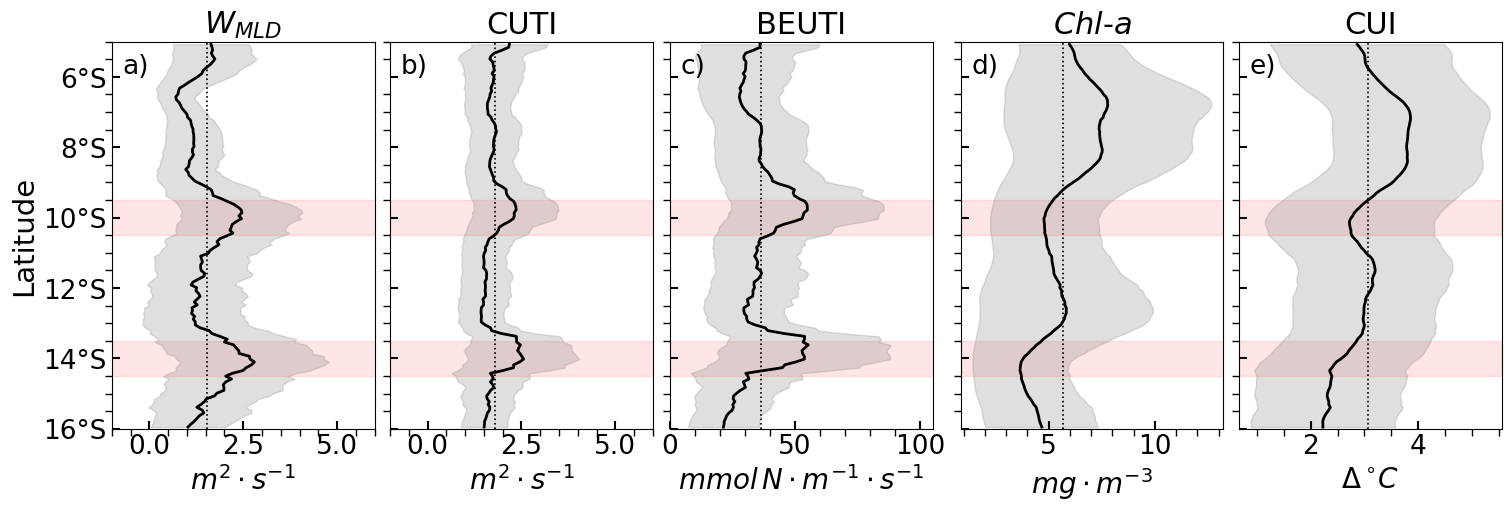

In [40]:
lsz = 6
# Publication font sizes
mpl.rcParams.update({
    'font.size':       14,
    'axes.titlesize':  16,
    'axes.labelsize':  15,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'pdf.fonttype':    42,
})


data_dict = {
    "WMLD":  W_L.rename({'lat_band': 'lat'}),
    "CUI":   CUI.CUI_cc,
    "CUTI":  CUTI.rename({'lat_band': 'lat'}),
    "BEUTI": BEUTI.rename({'lat_band': 'lat'}),
    "Chla": CHL.mean('lon').chla,
}

# New panel order
indx  = ['WMLD', 'CUTI', 'BEUTI', 'Chla', 'CUI']
units = [
    r'$m^{2} \cdot s^{-1}$',
    r'$m^{2} \cdot s^{-1}$',
    r'$mmol\,N \cdot m^{-1} \cdot s^{-1}$',
    r'$mg \cdot m^{-3}$',
    r'$\Delta\,^{\circ}C$',
]

# Pretty title labels (with subscripts and proper formatting)
title_labels = {
    'WMLD':  r'$W_{MLD}$',
    'CUTI':  'CUTI',
    'BEUTI': 'BEUTI',
    'CUI':   'CUI',
    'Chla':   r'$Chl\text{-}a$',
}

xlims = {
    'WMLD': (-1, 6),
    'CUTI': (-1, 6),
    'BEUTI': (0, 105),
}

def lat_formatter(y, _):
    if y == 0:
        return '0°'
    return f'{abs(int(y))}°{"S" if y < 0 else "N"}'

fig, axes = plt.subplots(1, 5, figsize=(15, 5), constrained_layout=True)
axes = np.array(axes).flatten()

for i, key in enumerate(indx):
    ax = axes[i]
    da = data_dict[key].sortby('lat')   # HR CUTI/BEUTI: latitude must run S -> N for slice(-16, -5)

    if da.lat.size > 15:
        mean = da.mean("time").rolling(lat=13, center=True).mean().sel(lat=slice(-16, -5))
        std  = da.std("time").rolling(lat=13, center=True).mean().sel(lat=slice(-16, -5))
        lat  = da.lat.sel(lat=slice(-16, -5))
    else:
        mean = da.mean("time")
        std  = da.std("time")
        lat  = da.lat

    if da.lat.size > 15:
        ax.plot(mean, lat, color="black", lw=2)
        ax.fill_betweenx(lat, mean - std, mean + std, alpha=0.25, color='gray')
    else:
        ax.errorbar(mean, lat, xerr=std, color='black', lw=2, marker='o', ms=4,
                    capsize=3, ecolor='gray', elinewidth=2)

    ax.axvline(mean.mean(), color='black', linestyle=':', lw=1.2, alpha=1)

    # Panel label a) ... e)
    ax.text(0.04, 0.97, f'{chr(97+i)})', transform=ax.transAxes,
            ha='left', va='top', fontsize=13+lsz)

    ax.set_title(title_labels[key], fontsize=16+lsz, fontweight='normal')
    ax.set_xlabel(units[i], fontsize=14+lsz)
    ax.set_ylim([-16, -5])

    # Highlight upwelling centers (5–6°S center removed)
    upwelling_centers = [(-10.5, -9.5), (-14.5, -13.5)]
    for ybot, ytop in upwelling_centers:
        ax.axhspan(ybot, ytop, color='red', alpha=0.1, zorder=0)

    ax.minorticks_on()
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(axis='both', labelsize=13+lsz, direction='in', size=6, width=1.5)
    ax.tick_params(which='minor', size=3+2, width=1)

    # Format latitude as "5°S", "10°S", etc.
    ax.yaxis.set_major_formatter(FuncFormatter(lat_formatter))

    if i == 0:
        ax.set_ylabel('Latitude', fontsize=15+lsz)
    else:
        ax.set_yticklabels([])

    if key in xlims:
        ax.set_xlim(xlims[key])

# --- Save ---
# with PdfPages('Figures/Indices_latitudinal_paper_new.pdf') as pdf:
#     pdf.savefig(fig, bbox_inches='tight', dpi=300)

plt.show()

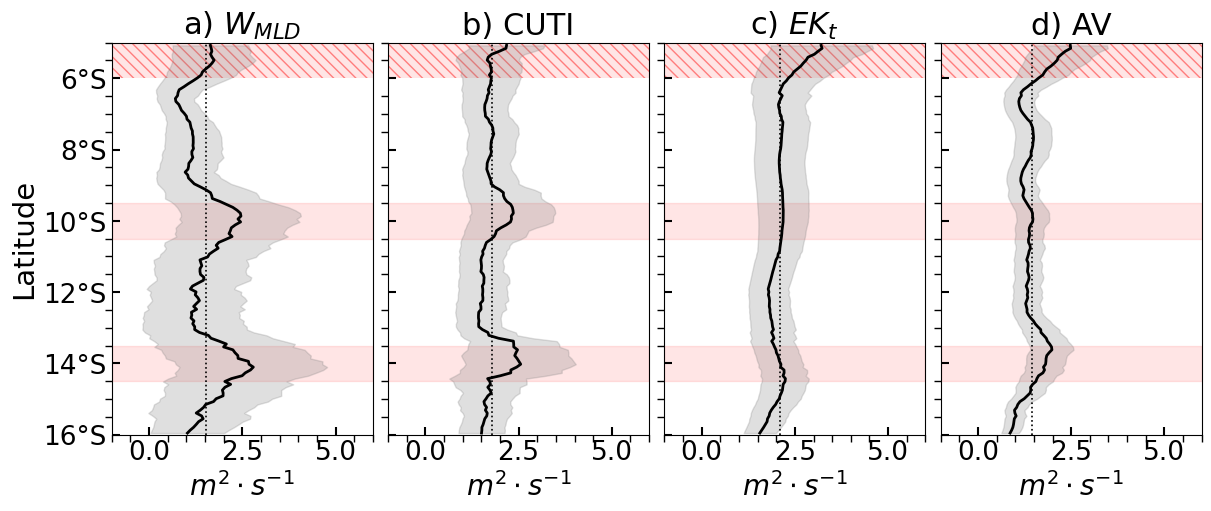

In [41]:
lsz = 6
# Publication font sizes
mpl.rcParams.update({
    'font.size':       14,
    'axes.titlesize':  16,
    'axes.labelsize':  15,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'pdf.fonttype':    42,
})

data_dict = {
    "WMLD":  W_L.rename({'lat_band': 'lat'}),
    "CUTI":  CUTI.rename({'lat_band': 'lat'}),
    "EkT":   Ek_t,
    "AV":    AV_L,
}

# Only WMLD, CUTI, EK_t, AV
indx  = ['WMLD', 'CUTI', 'EkT', 'AV']
units = [
    r'$m^{2} \cdot s^{-1}$',
    r'$m^{2} \cdot s^{-1}$',
    r'$m^{2} \cdot s^{-1}$',
    r'$m^{2} \cdot s^{-1}$',
]

title_labels = {
    'WMLD':  r'$W_{MLD}$',
    'CUTI':  'CUTI',
    'EkT':   r'$EK_t$',
    'AV':    'AV',
}

xlims = {
    'WMLD': (-1, 6),
    'CUTI': (-1, 6),
    'EkT':  (-1, 6),
    'AV':   (-1, 6),
}

def lat_formatter(y, _):
    if y == 0:
        return '0°'
    return f'{abs(int(y))}°{"S" if y < 0 else "N"}'

fig, axes = plt.subplots(1, 4, figsize=(12, 5), constrained_layout=True)
axes = np.array(axes).flatten()

# Upwelling centers: transient (plain red shade) and stationary (red shade + diagonal hatch)
upwelling_centers   = [(-10.5, -9.5), (-14.5, -13.5)]
stationary_centers  = [(-6, -5)]

for i, key in enumerate(indx):
    ax = axes[i]
    da = data_dict[key].sortby('lat')   # HR CUTI/BEUTI: latitude must run S -> N for slice(-16, -5)

    if da.lat.size > 15:
        mean = da.mean("time").rolling(lat=13, center=True).mean().sel(lat=slice(-16, -5))
        std  = da.std("time").rolling(lat=13, center=True).mean().sel(lat=slice(-16, -5))
        lat  = da.lat.sel(lat=slice(-16, -5))
    else:
        mean = da.mean("time")
        std  = da.std("time")
        lat  = da.lat

    if da.lat.size > 15:
        ax.plot(mean, lat, color="black", lw=2)
        ax.fill_betweenx(lat, mean - std, mean + std, alpha=0.25, color='gray')
    else:
        ax.errorbar(mean, lat, xerr=std, color='black', lw=2, marker='o', ms=4,
                    capsize=3, ecolor='gray', elinewidth=2)

    ax.axvline(mean.mean(), color='black', linestyle=':', lw=1.2, alpha=1)

    # Panel label a) ... d) as part of the title
    ax.set_title(f'{chr(97+i)}) ' + title_labels[key],
                 fontsize=16+lsz, fontweight='normal')
    ax.set_xlabel(units[i], fontsize=14+lsz)
    ax.set_ylim([-16, -5])

    # Transient upwelling centers: plain red shading
    for ybot, ytop in upwelling_centers:
        ax.axhspan(ybot, ytop, color='red', alpha=0.1, zorder=0)

    # Stationary upwelling center: red shading + single-direction diagonal lines
    for ybot, ytop in stationary_centers:
        ax.axhspan(ybot, ytop, facecolor='red', alpha=0.1, edgecolor='none', zorder=0)
        ax.axhspan(ybot, ytop, facecolor='none', edgecolor='red', alpha=0.45,
                   hatch='\\\\\\', linewidth=0, zorder=0)

    ax.minorticks_on()
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(axis='both', labelsize=13+lsz, direction='in', size=6, width=1.5)
    ax.tick_params(which='minor', size=3+2, width=1)

    ax.yaxis.set_major_formatter(FuncFormatter(lat_formatter))

    if i == 0:
        ax.set_ylabel('Latitude', fontsize=15+lsz)
    else:
        ax.set_yticklabels([])

    if key in xlims:
        ax.set_xlim(xlims[key])

# --- Save ---
# with PdfPages('Figures/Appendix_Indices_latitudinal_paper.pdf') as pdf:
#     pdf.savefig(fig, bbox_inches='tight', dpi=300)

plt.show()


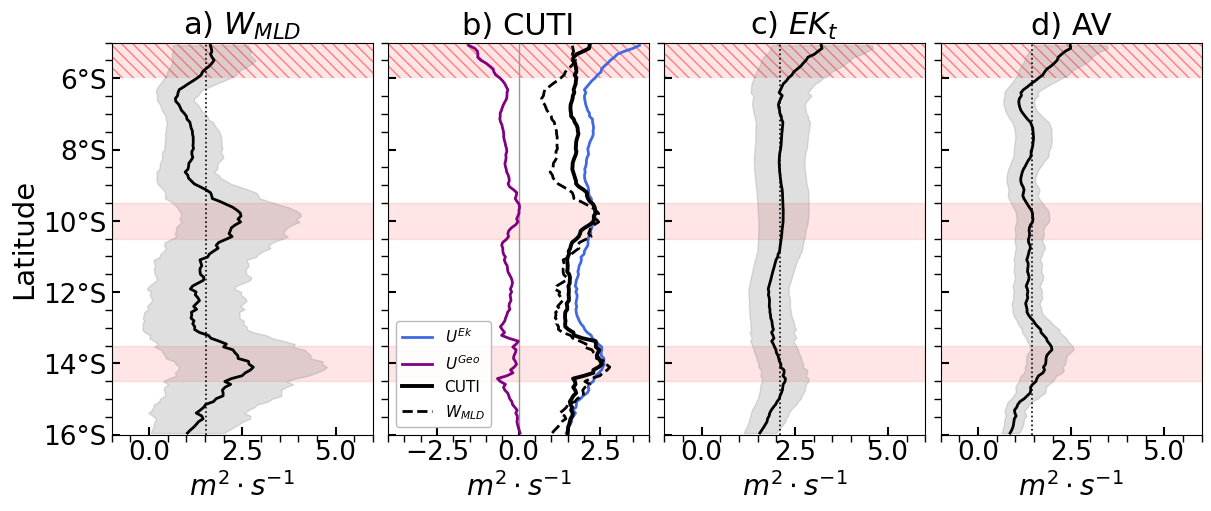

In [42]:
lsz = 6
# Publication font sizes
mpl.rcParams.update({
    'font.size':       14,
    'axes.titlesize':  16,
    'axes.labelsize':  15,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'pdf.fonttype':    42,
})

data_dict = {
    "WMLD":  W_L.rename({'lat_band': 'lat'}),
    "CUTI":  None,   # panel b) shows the CUTI components instead
    "EkT":   Ek_t,
    "AV":    AV_L,
}

# Only WMLD, CUTI components, EK_t, AV
indx  = ['WMLD', 'CUTI', 'EkT', 'AV']
units = [
    r'$m^{2} \cdot s^{-1}$',
    r'$m^{2} \cdot s^{-1}$',
    r'$m^{2} \cdot s^{-1}$',
    r'$m^{2} \cdot s^{-1}$',
]

title_labels = {
    'WMLD':  r'$W_{MLD}$',
    'CUTI':  'CUTI',
    'EkT':   r'$EK_t$',
    'AV':    'AV',
}

xlims = {
    'WMLD': (-1, 6),
    'CUTI': (-4, 4),
    'EkT':  (-1, 6),
    'AV':   (-1, 6),
}

def lat_formatter(y, _):
    if y == 0:
        return '0°'
    return f'{abs(int(y))}°{"S" if y < 0 else "N"}'

fig, axes = plt.subplots(1, 4, figsize=(12, 5), constrained_layout=True)
axes = np.array(axes).flatten()

# Upwelling centers: transient (plain red shade) and stationary (red shade + diagonal hatch)
upwelling_centers   = [(-10.5, -9.5), (-14.5, -13.5)]
stationary_centers  = [(-6, -5)]

for i, key in enumerate(indx):
    ax = axes[i]

    if key == 'CUTI':
        # CUTI components (as in CUTI_components_latitudinal_sp)
        ax.axvline(0, color='0.6', lw=1, zorder=1)
        for da, kw in [(hr.U_ek,             dict(color='royalblue', lw=2,   label='$U^{Ek}$')),
                       (hr.UGEO,             dict(color='purple',    lw=2,   label='$U^{Geo}$')),
                       (hr.CUTI,             dict(color='black',     lw=2.8, label='CUTI')),
                       (hr.W_L,             dict(color='black',     lw=2,   linestyle='--', label='$W_{MLD}$'))]:
            p_ = prof(da)
            ax.plot(p_, p_.lat_band, **kw)
        ax.legend(frameon=True, framealpha=0.9, edgecolor='0.7', loc='lower left', fontsize=11)
    else:
        da = data_dict[key].sortby('lat')

        if da.lat.size > 15:
            mean = da.mean("time").rolling(lat=13, center=True).mean().sel(lat=slice(-16, -5))
            std  = da.std("time").rolling(lat=13, center=True).mean().sel(lat=slice(-16, -5))
            lat  = da.lat.sel(lat=slice(-16, -5))
        else:
            mean = da.mean("time")
            std  = da.std("time")
            lat  = da.lat

        if da.lat.size > 15:
            ax.plot(mean, lat, color="black", lw=2)
            ax.fill_betweenx(lat, mean - std, mean + std, alpha=0.25, color='gray')
        else:
            ax.errorbar(mean, lat, xerr=std, color='black', lw=2, marker='o', ms=4,
                        capsize=3, ecolor='gray', elinewidth=2)

        ax.axvline(mean.mean(), color='black', linestyle=':', lw=1.2, alpha=1)

    # Panel label a) ... d) as part of the title
    ax.set_title(f'{chr(97+i)}) ' + title_labels[key],
                 fontsize=16+lsz, fontweight='normal')
    ax.set_xlabel(units[i], fontsize=14+lsz)
    ax.set_ylim([-16, -5])

    # Transient upwelling centers: plain red shading
    for ybot, ytop in upwelling_centers:
        ax.axhspan(ybot, ytop, color='red', alpha=0.1, zorder=0)

    # Stationary upwelling center: red shading + single-direction diagonal lines
    for ybot, ytop in stationary_centers:
        ax.axhspan(ybot, ytop, facecolor='red', alpha=0.1, edgecolor='none', zorder=0)
        ax.axhspan(ybot, ytop, facecolor='none', edgecolor='red', alpha=0.45,
                   hatch='\\\\\\', linewidth=0, zorder=0)

    ax.minorticks_on()
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(axis='both', labelsize=13+lsz, direction='in', size=6, width=1.5)
    ax.tick_params(which='minor', size=3+2, width=1)

    ax.yaxis.set_major_formatter(FuncFormatter(lat_formatter))

    if i == 0:
        ax.set_ylabel('Latitude', fontsize=15+lsz)
    else:
        ax.set_yticklabels([])

    if key in xlims:
        ax.set_xlim(xlims[key])

# --- Save ---
# with PdfPages('Figures/Appendix_Indices_latitudinal_paper.pdf') as pdf:
#     pdf.savefig(fig, bbox_inches='tight', dpi=300)

plt.show()